# 🌧️ Rota Seca: previsão de chuva extrema para quem mora em áreas que alagam

**FIAP · Global Solution 2026.2 · CitizenTech**
**Disciplina:** Data Science & Statistical Computing
**Curso:** Engenharia de Software, 2º ano (Fev)

| Integrante | RM |
|---|---|
| Felipe Bernardes | 564360 |
| Guilherme Romero | 564431 |

---

**Sumário**

1. Contexto, perguntas e variáveis-alvo
2. Fonte e dicionário dos dados
3. Carregamento
4. Preparação dos dados e divisão treino/teste (sem vazamento)
5. Análise exploratória (somente no treino)
6. Regressão linear: quanto vai chover no próximo mês?
7. Regressão logística: qual a chance de um dia de chuva extrema no próximo mês?
8. Aplicação na Rota Seca: estimativa para novembro de 2026
9. Recomendações de ação, impactos e limitações
10. Conclusão e referências

## 1. Contexto, perguntas e variáveis-alvo

### A CitizenTech
A **Rota Seca** é a CitizenTech da nossa equipe. Ela avisa moradores de áreas sujeitas a alagamento quando o risco de chuva forte aumenta e indica a rota mais segura até um ponto de apoio (abrigo, escola, UBS), desviando das ruas que costumam alagar.

- **Cidadão beneficiado:** morador de área de risco de alagamento em São Paulo, principalmente idosos, pessoas com mobilidade reduzida e quem volta do trabalho a pé ou de transporte público.
- **Problema, em uma frase:** quem mora em áreas que alagam não sabe com antecedência quando a chuva vai ser forte, nem qual caminho é seguro para sair ou voltar para casa.

### Onde a ciência de dados entra
Alagamentos urbanos estão fortemente ligados a **dias com grande volume de chuva**. O INMET classifica um acumulado de **50 a 100 mm em um dia** como aviso **laranja ("Perigo")**, com risco de alagamentos. Se a Rota Seca souber, com um mês de antecedência, **onde e quando** esse tipo de dia é mais provável, ela pode preparar a resposta: mutirões de limpeza de bueiros, conferência dos pontos de apoio e campanhas para cadastrar moradores que receberão alertas.

O modelo deste notebook é a **camada de planejamento** da Rota Seca (horizonte mensal). Os alertas de curto prazo (horas) continuam vindo dos avisos oficiais do INMET e da Defesa Civil, que a aplicação repassa ao morador.

### Perguntas
- **P1 (regressão linear):** quanto vai chover, em milímetros, no **próximo mês** em cada estação meteorológica do estado de São Paulo?
- **P2 (regressão logística):** qual a probabilidade de o **próximo mês** ter **pelo menos um dia com chuva ≥ 50 mm** (nível "Perigo" do INMET)?

### Variáveis-alvo
| Alvo | Tipo | Definição |
|---|---|---|
| `prec_prox` | numérica (mm) | Precipitação total do mês seguinte (t+1) na estação |
| `evento_prox` | binária (0/1) | 1 se o maior acumulado diário do mês seguinte (`pmax_dia` em t+1) for ≥ 50 mm; 0 caso contrário |

As **variáveis explicativas** são medidas no mês atual (t): chuva, temperatura, umidade, radiação, vento, localização da estação e o mês do ano que está sendo previsto. Assim, o modelo usa apenas informação disponível **antes** do mês previsto.

### Hipóteses
- **H1:** a sazonalidade (verão chuvoso, inverno seco) é o fator que mais explica o volume e o risco de chuva extrema.
- **H2:** um mês atual chuvoso e úmido indica maior volume no mês seguinte.
- **H3:** a localização (altitude, latitude, longitude) muda o padrão de chuva entre regiões do estado.

### ODS conectados
**ODS 11** (cidades e comunidades sustentáveis, meta 11.5: reduzir mortes e perdas causadas por desastres), **ODS 13** (ação contra a mudança do clima, meta 13.1: resiliência a riscos climáticos), **ODS 3** (saúde e bem-estar) e **ODS 10** (redução das desigualdades, já que as áreas que mais alagam costumam concentrar a população mais vulnerável).

## 2. Fonte e dicionário dos dados

**Fonte original:** INMET (Instituto Nacional de Meteorologia), dados históricos horários das estações meteorológicas automáticas. Portal: https://portal.inmet.gov.br/dadoshistoricos

**Consolidação usada:** arquivo `inmet_sp_mg_mensal.csv` do repositório público *analiseclimatica* (https://github.com/esthelaalmeida2025-rgb/analiseclimatica, pasta `docs/`). O script `atualizar.py` desse repositório baixa os arquivos do INMET e agrega os dados **horários → diários → mensais** por estação, para SP e MG, de 2020 até o mês mais recente. Arquivo baixado em **16/11/2026**.

Regras de qualidade aplicadas na origem (conferidas no script):
- leituras horárias de chuva negativas ou acima de 200 mm são descartadas;
- dias com menos de 18 leituras horárias válidas ficam sem valor;
- meses com cobertura de chuva abaixo de 80% (`cob_prec`) ficam com chuva vazia (NaN).

Não há dados pessoais na base: são apenas medições de estações meteorológicas.

| Coluna | Descrição |
|---|---|
| `uf`, `codigo`, `estacao` | Estado, código e nome da estação do INMET |
| `lat`, `lon`, `alt` | Latitude, longitude e altitude (m) da estação |
| `ano_mes` | Mês de referência (AAAA-MM) |
| `prec` | Precipitação total do mês (mm) |
| `dias_chuva` | Dias com chuva ≥ 1 mm |
| `pmax_dia` | Maior acumulado de chuva em um único dia do mês (mm) |
| `tmed`, `tmax_med`, `tmin_med` | Temperatura média, média das máximas e média das mínimas (°C) |
| `tmax_abs`, `tmin_abs` | Temperatura máxima e mínima absolutas do mês (°C) |
| `umid`, `umin` | Umidade relativa média e mínima (%) |
| `rad` | Radiação global média diária (MJ/m²) |
| `vel`, `raj` | Velocidade média do vento e rajada máxima (m/s) |
| `dias_geada`, `dias_calor` | Dias com mínima ≤ 3 °C e dias com máxima ≥ 32 °C |
| `cob_prec`, `cob_temp` | % de dias do mês com dado válido de chuva e de temperatura |

> **Como executar:** Python 3.10+ com `pandas`, `numpy`, `matplotlib`, `seaborn` e `scikit-learn`. Deixe o arquivo `inmet_sp_mg_mensal.csv` na mesma pasta deste notebook e use *Run All*.

## 3. Carregamento

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             classification_report, roc_auc_score, RocCurveDisplay)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

ARQUIVO = 'inmet_sp_mg_mensal.csv'
bruto = pd.read_csv(ARQUIVO, sep=';', decimal=',', encoding='utf-8-sig')
print(f'Linhas: {bruto.shape[0]} | Colunas: {bruto.shape[1]}')
bruto.head()

Linhas: 8883 | Colunas: 24


,uf,codigo,estacao,lat,lon,alt,ano_mes,prec,dias_chuva,pmax_dia,tmed,tmax_med,tmin_med,tmax_abs,tmin_abs,umid,umin,rad,vel,raj,dias_geada,dias_calor,cob_prec,cob_temp
0,MG,A549,Aguas Vermelhas,-15.7515,-41.4578,754.07,2020-01,130.40,13.00,50.20,23.70,31.10,18.40,35.60,14.50,72.00,17.00,21.20,2.10,15.60,0.00,13.00,100.00,100.00
1,MG,A549,Aguas Vermelhas,-15.7515,-41.4578,754.07,2020-02,58.00,2.00,55.80,24.00,32.00,18.10,35.40,15.00,69.00,21.00,21.30,1.80,14.70,0.00,14.00,100.00,100.00
2,MG,A549,Aguas Vermelhas,-15.7515,-41.4578,754.07,2020-03,198.60,14.00,39.20,22.30,28.00,18.70,33.10,16.00,80.00,32.00,15.70,1.70,14.90,0.00,3.00,100.00,100.00
3,MG,A549,Aguas Vermelhas,-15.7515,-41.4578,754.07,2020-04,104.40,8.00,53.40,21.50,27.30,17.50,34.70,10.40,82.00,28.00,14.90,1.50,15.30,0.00,3.00,100.00,100.00
4,MG,A549,Aguas Vermelhas,-15.7515,-41.4578,754.07,2020-05,38.40,5.00,27.60,19.70,26.10,15.50,31.50,7.20,82.00,27.00,13.40,1.40,12.40,0.00,0.00,100.00,100.00


In [3]:
bruto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8883 entries, 0 to 8882
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   uf          8883 non-null   object 
 1   codigo      8883 non-null   object 
 2   estacao     8883 non-null   object 
 3   lat         8883 non-null   object 
 4   lon         8883 non-null   object 
 5   alt         8883 non-null   object 
 6   ano_mes     8883 non-null   object 
 7   prec        6839 non-null   float64
 8   dias_chuva  6839 non-null   float64
 9   pmax_dia    6839 non-null   float64
 10  tmed        7507 non-null   float64
 11  tmax_med    7507 non-null   float64
 12  tmin_med    7507 non-null   float64
 13  tmax_abs    7507 non-null   float64
 14  tmin_abs    7507 non-null   float64
 15  umid        7446 non-null   float64
 16  umin        7445 non-null   float64
 17  rad         8084 non-null   float64
 18  vel         7082 non-null   float64
 19  raj         7085 non-null  

## 4. Preparação dos dados

### 4.1 Filtro do estado de São Paulo e conversão de tipos
A base traz SP e MG. A Rota Seca atua em São Paulo, então mantemos só as estações paulistas. As colunas `lat`, `lon` e `alt` vieram como texto e são convertidas para número, e `ano_mes` vira um período mensal.

In [4]:
df = bruto[bruto['uf'] == 'SP'].copy()
for c in ['lat', 'lon', 'alt']:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')
df['periodo'] = pd.PeriodIndex(df['ano_mes'], freq='M')

print(f"Estações de SP: {df['codigo'].nunique()}")
print(f"Período: {df['periodo'].min()} a {df['periodo'].max()}")
print(f"Linhas: {len(df)} | Duplicatas estação+mês: {df.duplicated(['codigo','periodo']).sum()}")

Estações de SP: 43
Período: 2020-01 a 2026-10
Linhas: 3314 | Duplicatas estação+mês: 0


### 4.2 Qualidade dos dados
Verificamos valores faltantes e valores fisicamente impossíveis.

In [5]:
faltantes = (df.isna().mean() * 100).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0].round(1).rename('% faltante').to_frame()
faltantes

,% faltante
prec,31.70
dias_chuva,31.70
pmax_dia,31.70
vel,27.90
raj,27.90
umin,23.10
umid,23.10
tmax_med,22.20
tmin_med,22.20
tmax_abs,22.20


In [6]:
print('Estatísticas da radiação (MJ/m² por dia):')
print(df['rad'].describe().round(2))
print(f"\nMeses com radiação > 40 MJ/m²/dia: {(df['rad'] > 40).sum()}")
print(f"Meses com radiação = 0: {(df['rad'] == 0).sum()}")

Estatísticas da radiação (MJ/m² por dia):
count   2,850.00
mean       17.01
std         4.50
min         0.00
25%        14.30
50%        17.10
75%        19.80
max        60.30
Name: rad, dtype: float64

Meses com radiação > 40 MJ/m²/dia: 5
Meses com radiação = 0: 2


A radiação solar global no topo da atmosfera nas latitudes de São Paulo fica perto de 40 a 45 MJ/m² por dia no verão, e na superfície é menor. Médias mensais acima de 40 ou iguais a 0 indicam erro de sensor, então esses valores viram **NaN** e serão tratados pela imputação dentro do pipeline.

As outras colunas ficaram dentro de faixas plausíveis (por exemplo, chuva mensal de 0 a 627 mm e temperatura média de 9,6 a 28 °C).

In [7]:
df.loc[(df['rad'] > 40) | (df['rad'] == 0), 'rad'] = np.nan
df['amplitude'] = df['tmax_med'] - df['tmin_med']   # amplitude térmica média do mês

### 4.3 Série mensal contínua por estação e construção dos alvos
Para prever o mês **t+1** a partir do mês **t**, precisamos garantir que a "próxima linha" de uma estação seja de fato o mês seguinte. Algumas estações têm meses inteiros ausentes, então reindexamos cada estação com **todos os meses** do seu período e só então deslocamos (`shift(-1)`) as colunas de chuva para criar os alvos.

- `prec_prox` = `prec` do mês seguinte
- `pmax_prox` = `pmax_dia` do mês seguinte
- `evento_prox` = 1 se `pmax_prox` ≥ 50 mm (aviso laranja do INMET)

Também codificamos o **mês previsto** de forma cíclica (`mes_sin`, `mes_cos`), para que dezembro e janeiro fiquem próximos, como são no clima.

In [8]:
LIMIAR_MM = 50

partes = []
for codigo, g in df.groupby('codigo'):
    g = g.set_index('periodo').sort_index()
    meses = pd.period_range(g.index.min(), g.index.max(), freq='M')
    g = g.reindex(meses)
    g.index.name = 'periodo'
    for c in ['uf', 'codigo', 'estacao', 'lat', 'lon', 'alt']:
        g[c] = g[c].ffill().bfill()
    g['prec_prox'] = g['prec'].shift(-1)
    g['pmax_prox'] = g['pmax_dia'].shift(-1)
    partes.append(g.reset_index())

dados = pd.concat(partes, ignore_index=True)
dados['periodo_alvo'] = dados['periodo'] + 1
mes_alvo = dados['periodo_alvo'].dt.month
dados['mes_sin'] = np.sin(2 * np.pi * mes_alvo / 12)
dados['mes_cos'] = np.cos(2 * np.pi * mes_alvo / 12)
dados['evento_prox'] = np.where(dados['pmax_prox'].isna(), np.nan,
                                (dados['pmax_prox'] >= LIMIAR_MM).astype(float))

print(f'Linhas após reindexação: {len(dados)}')
print(f"Linhas com alvo numérico disponível: {dados['prec_prox'].notna().sum()}")
print(f"Linhas com alvo binário disponível: {dados['evento_prox'].notna().sum()}")
dados[['codigo','periodo','prec','periodo_alvo','prec_prox','pmax_prox','evento_prox']].head(8)

Linhas após reindexação: 3338
Linhas com alvo numérico disponível: 2229
Linhas com alvo binário disponível: 2229


,codigo,periodo,prec,periodo_alvo,prec_prox,pmax_prox,evento_prox
0,A701,2020-01,279.20,2020-02,493.80,143.00,1.00
1,A701,2020-02,493.80,2020-03,69.40,14.80,0.00
2,A701,2020-03,69.40,2020-04,7.40,6.60,0.00
3,A701,2020-04,7.40,2020-05,11.00,5.20,0.00
4,A701,2020-05,11.00,2020-06,152.40,113.60,1.00
5,A701,2020-06,152.40,2020-07,12.60,11.60,0.00
6,A701,2020-07,12.60,2020-08,66.20,17.80,0.00
7,A701,2020-08,66.20,2020-09,14.60,11.60,0.00


### 4.4 Variáveis explicativas
Escolhemos variáveis que representam o estado do tempo no mês atual, a localização e a época do ano. Para reduzir a colinearidade entre temperaturas, usamos `tmed` e a `amplitude` térmica em vez de máxima e mínima separadas.

In [9]:
FEATURES = ['prec', 'dias_chuva', 'pmax_dia',
            'tmed', 'amplitude', 'umid', 'rad', 'vel',
            'lat', 'lon', 'alt',
            'mes_sin', 'mes_cos']
ALVO_REG = 'prec_prox'
ALVO_CLF = 'evento_prox'

### 4.5 Divisão treino/teste temporal, sem vazamento de dados
Como são dados no tempo, uma divisão aleatória misturaria meses de 2026 no treino e de 2021 no teste, e o modelo "veria o futuro". Por isso usamos **divisão temporal**:

- **Treino:** meses previstos de **fev/2020 a dez/2024**
- **Teste:** meses previstos de **jan/2025 a out/2026** (dados que o modelo nunca viu)

Cuidados contra vazamento:
1. As variáveis explicativas são do mês **t** e o alvo é do mês **t+1**. Nenhuma informação do mês previsto entra como entrada.
2. A divisão é feita **antes** de qualquer imputação ou padronização.
3. A **imputação (mediana)** e a **padronização** ficam dentro de um `Pipeline`, então são ajustadas **somente no treino** e apenas aplicadas no teste.
4. A análise exploratória da seção 5 usa **somente o treino**.

In [10]:
CORTE = pd.Period('2024-12', freq='M')
treino = dados[dados['periodo_alvo'] <= CORTE].copy()
teste  = dados[dados['periodo_alvo'] >  CORTE].copy()

treino_reg = treino.dropna(subset=[ALVO_REG]); teste_reg = teste.dropna(subset=[ALVO_REG])
treino_clf = treino.dropna(subset=[ALVO_CLF]); teste_clf = teste.dropna(subset=[ALVO_CLF])

X_tr_reg, y_tr_reg = treino_reg[FEATURES], treino_reg[ALVO_REG]
X_te_reg, y_te_reg = teste_reg[FEATURES],  teste_reg[ALVO_REG]
X_tr_clf, y_tr_clf = treino_clf[FEATURES], treino_clf[ALVO_CLF].astype(int)
X_te_clf, y_te_clf = teste_clf[FEATURES],  teste_clf[ALVO_CLF].astype(int)

resumo = pd.DataFrame({
    'linhas': [len(treino_reg), len(teste_reg)],
    'primeiro mês previsto': [treino_reg['periodo_alvo'].min(), teste_reg['periodo_alvo'].min()],
    'último mês previsto':   [treino_reg['periodo_alvo'].max(), teste_reg['periodo_alvo'].max()],
    '% meses com evento ≥50mm': [y_tr_clf.mean()*100, y_te_clf.mean()*100],
}, index=['treino', 'teste'])
print(f"Sobreposição de meses entre treino e teste: {len(set(treino_reg['periodo_alvo']) & set(teste_reg['periodo_alvo']))}")
resumo

Sobreposição de meses entre treino e teste: 0


,linhas,primeiro mês previsto,último mês previsto,% meses com evento ≥50mm
treino,1606,2020-02,2024-12,21.73
teste,623,2025-01,2026-10,23.27


## 5. Análise exploratória (somente no conjunto de treino)

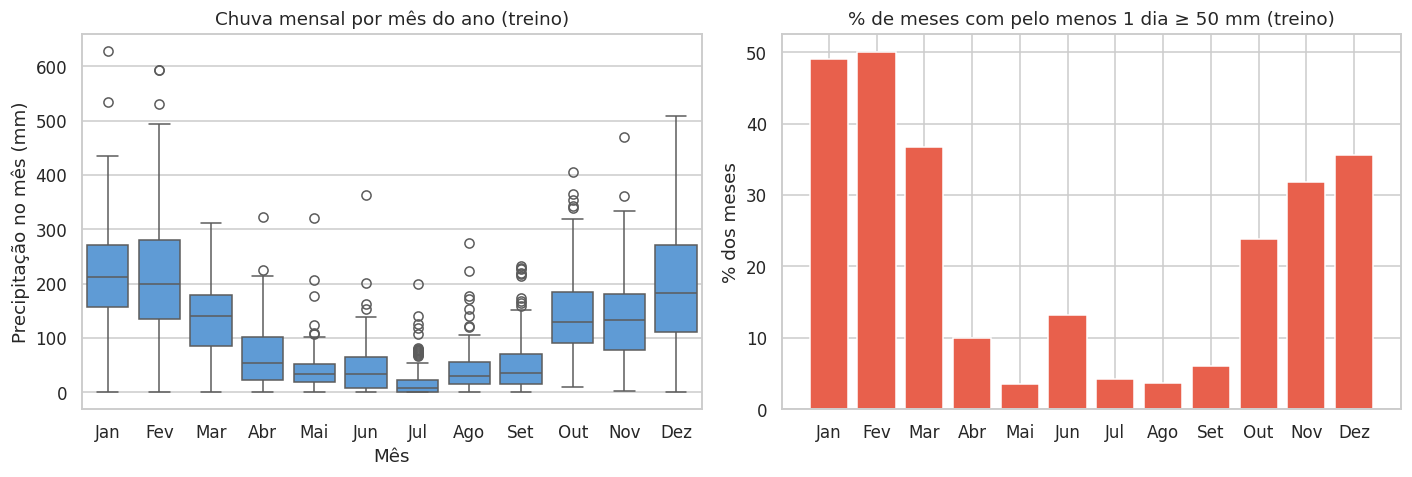

In [11]:
eda = treino_reg.copy()
eda['mes'] = eda['periodo_alvo'].dt.month
nomes_meses = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=eda, x='mes', y='prec_prox', ax=ax[0], color='#4C9BE8')
ax[0].set_xticklabels(nomes_meses)
ax[0].set(title='Chuva mensal por mês do ano (treino)', xlabel='Mês', ylabel='Precipitação no mês (mm)')

taxa = treino_clf.assign(mes=treino_clf['periodo_alvo'].dt.month).groupby('mes')[ALVO_CLF].mean() * 100
ax[1].bar(nomes_meses, taxa.values, color='#E8604C')
ax[1].set(title='% de meses com pelo menos 1 dia ≥ 50 mm (treino)', ylabel='% dos meses')
plt.tight_layout(); plt.show()

A sazonalidade é muito forte: de **novembro a março** a chuva mensal e a chance de um dia com 50 mm ou mais são muito maiores do que no inverno (junho a agosto), quando esse tipo de evento quase não acontece. Isso apoia a **H1** e justifica incluir o mês previsto como variável.

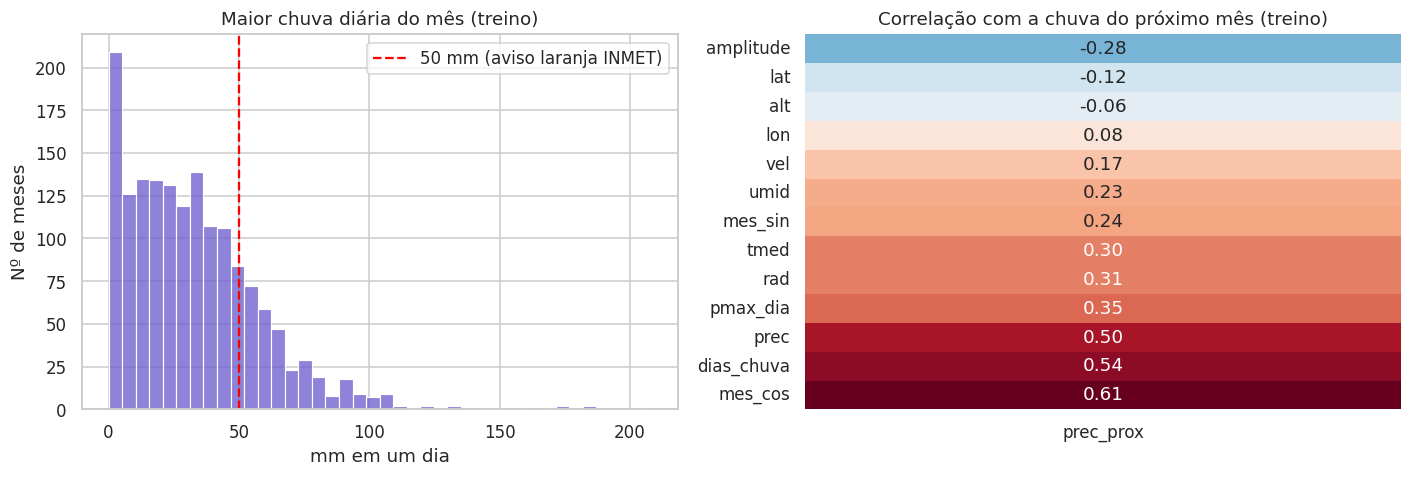

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(treino_clf['pmax_prox'], bins=40, ax=ax[0], color='#6A5ACD')
ax[0].axvline(LIMIAR_MM, color='red', ls='--', label='50 mm (aviso laranja INMET)')
ax[0].set(title='Maior chuva diária do mês (treino)', xlabel='mm em um dia', ylabel='Nº de meses')
ax[0].legend()

corr = treino_reg[FEATURES + [ALVO_REG]].corr()[[ALVO_REG]].drop(ALVO_REG).sort_values(ALVO_REG)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[1], cbar=False)
ax[1].set(title='Correlação com a chuva do próximo mês (treino)')
plt.tight_layout(); plt.show()

- A distribuição da maior chuva diária é assimétrica: a maioria dos meses fica abaixo de 50 mm, e os eventos acima do limiar são a minoria (por volta de 1 em cada 5 meses). Isso é um **desbalanceamento de classes** que será tratado na regressão logística.
- `mes_cos` tem a maior correlação com a chuva do mês seguinte (meses próximos de dezembro/janeiro têm cosseno perto de 1). A chuva, os dias de chuva e a temperatura do mês atual também têm correlação positiva, o que apoia a **H2**.

## 6. Regressão linear: quanto vai chover no próximo mês?

### 6.1 Linhas de base
Antes do modelo, calculamos duas referências simples para saber se ele agrega valor:
- **Média geral:** prever sempre a chuva média do treino.
- **Climatologia:** prever a média histórica (do treino) daquela estação para aquele mês do ano. É o que um meteorologista usaria como "normal".

In [13]:
def metricas_reg(y, p):
    return {'MAE (mm)': mean_absolute_error(y, p),
            'RMSE (mm)': np.sqrt(mean_squared_error(y, p)),
            'R²': r2_score(y, p)}

media_treino = y_tr_reg.mean()
clim_est = treino_reg.groupby(['codigo', treino_reg['periodo_alvo'].dt.month])[ALVO_REG].mean()
clim_mes = treino_reg.groupby(treino_reg['periodo_alvo'].dt.month)[ALVO_REG].mean()
def climatologia(base):
    chaves = list(zip(base['codigo'], base['periodo_alvo'].dt.month))
    valores = pd.Series(chaves).map(clim_est.to_dict())
    reserva = base['periodo_alvo'].dt.month.map(clim_mes).values
    return np.where(valores.isna(), reserva, valores)

base_media = metricas_reg(y_te_reg, np.full(len(y_te_reg), media_treino))
base_clim  = metricas_reg(y_te_reg, climatologia(teste_reg))

### 6.2 Treinamento do modelo

In [14]:
modelo_lin = Pipeline([
    ('imputacao', SimpleImputer(strategy='median')),
    ('padronizacao', StandardScaler()),
    ('regressao', LinearRegression())
])
modelo_lin.fit(X_tr_reg, y_tr_reg)

pred_tr_reg = modelo_lin.predict(X_tr_reg)
pred_te_reg = modelo_lin.predict(X_te_reg)

tabela_reg = pd.DataFrame({
    'Regressão linear (treino)': metricas_reg(y_tr_reg, pred_tr_reg),
    'Regressão linear (teste)':  metricas_reg(y_te_reg, pred_te_reg),
    'Base: média geral (teste)': base_media,
    'Base: climatologia (teste)': base_clim,
}).T
tabela_reg

,MAE (mm),RMSE (mm),R²
Regressão linear (treino),51.99,72.85,0.48
Regressão linear (teste),54.08,73.32,0.44
Base: média geral (teste),77.77,98.09,-0.00
Base: climatologia (teste),52.96,74.72,0.42


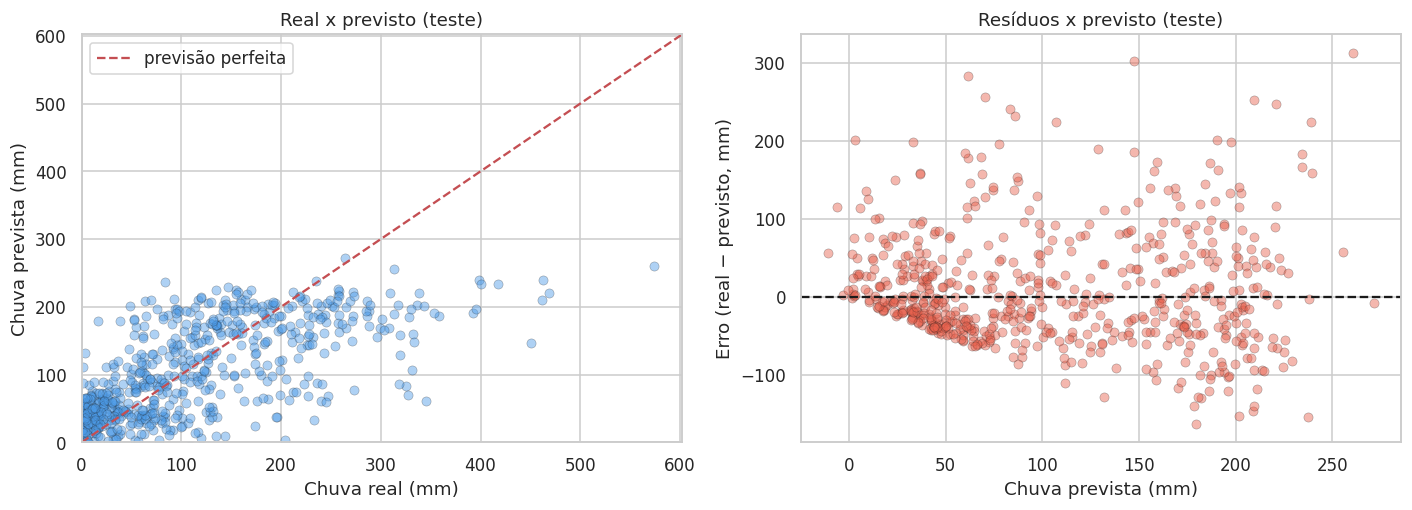

Previsões negativas no teste: 4 de 623


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(y_te_reg, pred_te_reg, alpha=0.45, color='#4C9BE8', edgecolor='k', linewidth=0.3)
lim = [0, max(y_te_reg.max(), pred_te_reg.max()) * 1.05]
ax[0].plot(lim, lim, 'r--', label='previsão perfeita')
ax[0].set(xlim=lim, ylim=lim, title='Real x previsto (teste)', xlabel='Chuva real (mm)', ylabel='Chuva prevista (mm)')
ax[0].legend()

residuos = y_te_reg - pred_te_reg
ax[1].scatter(pred_te_reg, residuos, alpha=0.45, color='#E8604C', edgecolor='k', linewidth=0.3)
ax[1].axhline(0, color='k', ls='--')
ax[1].set(title='Resíduos x previsto (teste)', xlabel='Chuva prevista (mm)', ylabel='Erro (real − previsto, mm)')
plt.tight_layout(); plt.show()
print(f'Previsões negativas no teste: {(pred_te_reg < 0).sum()} de {len(pred_te_reg)}')

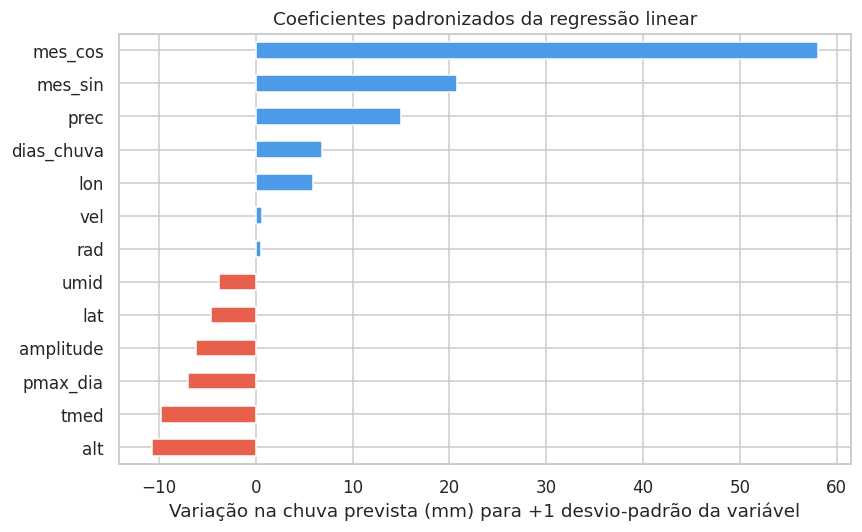

Intercepto (chuva prevista com todas as variáveis na média): 107.1 mm


In [16]:
coef = pd.Series(modelo_lin.named_steps['regressao'].coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
coef.plot.barh(ax=ax, color=np.where(coef > 0, '#4C9BE8', '#E8604C'))
ax.set(title='Coeficientes padronizados da regressão linear',
       xlabel='Variação na chuva prevista (mm) para +1 desvio-padrão da variável')
plt.tight_layout(); plt.show()
print(f"Intercepto (chuva prevista com todas as variáveis na média): {modelo_lin.named_steps['regressao'].intercept_:.1f} mm")

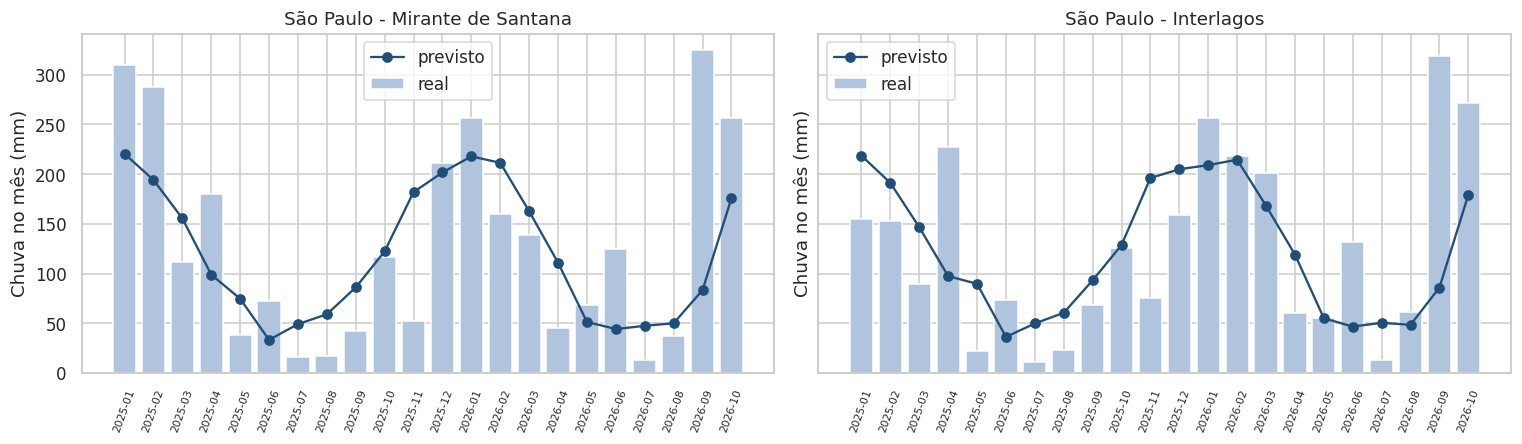

In [17]:
# Série real x prevista para as estações da capital no período de teste
capital = {'A701': 'São Paulo - Mirante de Santana', 'A771': 'São Paulo - Interlagos'}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for i, (cod, nome) in enumerate(capital.items()):
    s = teste_reg[teste_reg['codigo'] == cod]
    p = modelo_lin.predict(s[FEATURES])
    x = s['periodo_alvo'].astype(str)
    ax[i].bar(x, s[ALVO_REG], color='#B0C4DE', label='real')
    ax[i].plot(x, p, 'o-', color='#1F4E79', label='previsto')
    ax[i].set(title=nome, ylabel='Chuva no mês (mm)')
    ax[i].tick_params(axis='x', rotation=70, labelsize=7)
    ax[i].legend()
plt.tight_layout(); plt.show()

### 6.3 Interpretação da regressão linear

**Desempenho.** No teste (jan/2025 a out/2026, meses que o modelo nunca viu), a regressão linear teve **MAE de 54,1 mm**, **RMSE de 73,3 mm** e **R² de 0,44**. Ou seja, explica cerca de 44% da variação da chuva do mês seguinte, e erra em média 54 mm para mais ou para menos.

**Comparação com as linhas de base.**
- Contra a **média geral** (MAE 77,8 mm, R² ≈ 0), o modelo reduz o erro médio em cerca de **30%**. Ele aprendeu um padrão real.
- Contra a **climatologia** (MAE 53,0 mm, RMSE 74,7 mm, R² 0,42), o modelo fica praticamente empatado no MAE e um pouco melhor no RMSE e no R². Isso mostra que **a maior parte do poder de previsão vem da sazonalidade** (confirma a **H1**) e que as condições do mês atual acrescentam um ganho pequeno, principalmente reduzindo erros grandes.

**Generalização.** O R² caiu pouco do treino (0,48) para o teste (0,44), e o MAE subiu só 2 mm. Não há sinal de sobreajuste: o modelo se comporta de forma parecida em um período novo.

**Coeficientes** (efeito em mm de +1 desvio-padrão em cada variável, mantendo as outras fixas):
- `mes_cos` (**+58 mm**) é de longe o maior efeito: meses próximos de dezembro/janeiro são muito mais chuvosos. `mes_sin` (+21 mm) indica que, para a mesma distância do verão, o início do ano (fev/mar) chove mais que o fim (out/nov).
- `prec` do mês atual (**+15 mm**) mostra **persistência**: um mês chuvoso tende a ser seguido por outro chuvoso. Isso confirma parcialmente a **H2**.
- `alt` (−11 mm), `lon` (+6 mm) e `lat` (−5 mm): estações mais baixas, mais a leste e mais ao sul (em direção ao litoral e à Serra do Mar) recebem mais chuva. Isso confirma a **H3**.
- `tmed` (−10 mm) e `amplitude` (−6 mm) são negativos, apesar de a correlação simples da temperatura com a chuva ser positiva. A explicação é que a correlação simples mistura o efeito da estação do ano (verão é quente e chuvoso). **Dentro do mesmo mês do ano**, um mês mais quente e com maior amplitude térmica (céu aberto, ar seco) tende a anteceder menos chuva. É um exemplo de variável de confusão.
- `pmax_dia` (−7 mm) aparece negativo junto com `prec` positivo porque as duas variáveis são correlacionadas. Coeficientes de variáveis colineares devem ser lidos em conjunto, não isoladamente.

**Resíduos.** O erro cresce quando a chuva prevista é maior (heterocedasticidade). O MAE é de 67 mm nos meses chuvosos (nov a mar) e de 47 mm nos meses secos. O modelo também **subestima meses extremos**: a maior previsão no teste foi 272 mm, enquanto o maior valor real foi 574 mm. Por isso a regressão linear serve para indicar se o mês tende a ficar **acima ou abaixo do normal**, e a regressão logística (próxima seção) é que trata diretamente dos eventos extremos. Houve 4 previsões negativas em 623 (meses secos), que na aplicação são cortadas para 0 mm.

Nas duas estações da capital, o MAE no teste foi de cerca de 59 mm (Mirante de Santana) e 58 mm (Interlagos), em 22 meses cada.

## 7. Regressão logística: qual a chance de um dia de chuva extrema no próximo mês?

Como só cerca de 1 em cada 5 meses tem um dia com 50 mm ou mais, usamos `class_weight='balanced'`, que dá mais peso aos meses com evento. Para a Rota Seca, **deixar de avisar sobre um mês perigoso (falso negativo) é pior do que preparar o bairro à toa (falso positivo)**, então priorizamos o **recall** sem abrir mão de uma precisão razoável. O limiar de decisão foi fixado em **0,5 antes** de olharmos o teste.

In [18]:
modelo_log = Pipeline([
    ('imputacao', SimpleImputer(strategy='median')),
    ('padronizacao', StandardScaler()),
    ('logistica', LogisticRegression(class_weight='balanced', max_iter=2000))
])
modelo_log.fit(X_tr_clf, y_tr_clf)

prob_te = modelo_log.predict_proba(X_te_clf)[:, 1]
pred_te_clf = (prob_te >= 0.5).astype(int)
pred_tr_clf = modelo_log.predict(X_tr_clf)

def metricas_clf(y, p, prob=None):
    m = {'Precisão': precision_score(y, p), 'Recall': recall_score(y, p), 'F1': f1_score(y, p)}
    if prob is not None: m['ROC AUC'] = roc_auc_score(y, prob)
    return m

tabela_clf = pd.DataFrame({
    'Logística (treino)': metricas_clf(y_tr_clf, pred_tr_clf, modelo_log.predict_proba(X_tr_clf)[:, 1]),
    'Logística (teste)':  metricas_clf(y_te_clf, pred_te_clf, prob_te),
}).T
tabela_clf

,Precisão,Recall,F1,ROC AUC
Logística (treino),0.39,0.76,0.52,0.77
Logística (teste),0.44,0.74,0.55,0.78


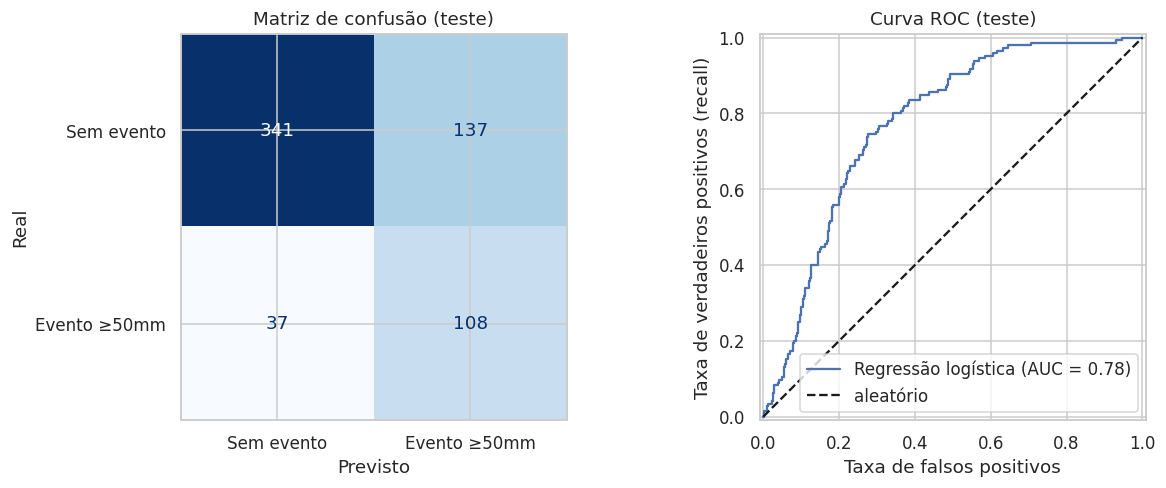

Verdadeiros negativos: 341 | Falsos positivos: 137 | Falsos negativos: 37 | Verdadeiros positivos: 108

              precision    recall  f1-score   support

  Sem evento      0.902     0.713     0.797       478
Evento ≥50mm      0.441     0.745     0.554       145

    accuracy                          0.721       623
   macro avg      0.671     0.729     0.675       623
weighted avg      0.795     0.721     0.740       623



In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
cm = confusion_matrix(y_te_clf, pred_te_clf)
ConfusionMatrixDisplay(cm, display_labels=['Sem evento', 'Evento ≥50mm']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set(title='Matriz de confusão (teste)', xlabel='Previsto', ylabel='Real')
RocCurveDisplay.from_predictions(y_te_clf, prob_te, ax=ax[1], name='Regressão logística')
ax[1].plot([0, 1], [0, 1], 'k--', label='aleatório'); ax[1].legend()
ax[1].set(title='Curva ROC (teste)', xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos (recall)')
plt.tight_layout(); plt.show()

vn, fp, fn, vp = cm.ravel()
print(f'Verdadeiros negativos: {vn} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdadeiros positivos: {vp}')
print()
print(classification_report(y_te_clf, pred_te_clf, target_names=['Sem evento', 'Evento ≥50mm'], digits=3))

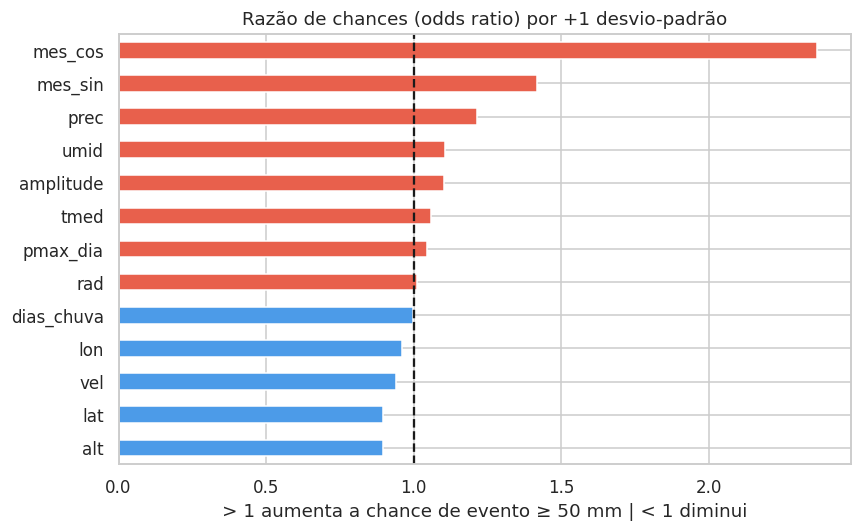

In [20]:
odds = pd.Series(np.exp(modelo_log.named_steps['logistica'].coef_[0]), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
odds.plot.barh(ax=ax, color=np.where(odds > 1, '#E8604C', '#4C9BE8'))
ax.axvline(1, color='k', ls='--')
ax.set(title='Razão de chances (odds ratio) por +1 desvio-padrão',
       xlabel='> 1 aumenta a chance de evento ≥ 50 mm | < 1 diminui')
plt.tight_layout(); plt.show()

**Análise de sensibilidade do limiar (apenas para discussão).** O limiar operacional continua 0,5. A tabela abaixo mostra o que aconteceria com outros limiares, para orientar a calibração futura com dados novos.

In [21]:
linhas = []
for lim in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (prob_te >= lim).astype(int)
    linhas.append({'limiar': lim, 'meses sinalizados': p.sum(),
                   'eventos capturados': int(((p == 1) & (y_te_clf == 1)).sum()),
                   'eventos perdidos': int(((p == 0) & (y_te_clf == 1)).sum()),
                   'precisão': precision_score(y_te_clf, p, zero_division=0),
                   'recall': recall_score(y_te_clf, p), 'F1': f1_score(y_te_clf, p)})
pd.DataFrame(linhas).set_index('limiar')

,meses sinalizados,eventos capturados,eventos perdidos,precisão,recall,F1
limiar,,,,,,
0.30,347,125,20,0.36,0.86,0.51
0.40,293,117,28,0.40,0.81,0.53
0.50,245,108,37,0.44,0.74,0.55
0.60,184,86,59,0.47,0.59,0.52
0.70,124,58,87,0.47,0.40,0.43


### 7.1 Interpretação da regressão logística

**O que a matriz de confusão mostra.** No teste houve **145 meses com pelo menos um dia de chuva ≥ 50 mm**. O modelo sinalizou **108** deles com um mês de antecedência (**recall de 74,5%**) e deixou passar **37**. Ele sinalizou 245 meses ao todo, dos quais 108 realmente tiveram o evento (**precisão de 44%**), o que significa **137 alarmes falsos**.

**Métricas.** F1 de **0,55** e ROC AUC de **0,78**. A AUC indica que, sorteando um mês com evento e um sem evento, o modelo dá probabilidade maior ao mês com evento em 78% das vezes.

**Isso é bom?** Três comparações ajudam:
- Um modelo que sempre diz "não vai ter evento" acertaria 76,7% dos meses, mas teria **recall zero**: nunca avisaria ninguém. Para a Rota Seca ele é inútil. Nossa acurácia é de 72%, mas capturamos 3 de cada 4 meses perigosos.
- Se a Rota Seca sinalizasse os mesmos 245 meses **ao acaso**, capturaria em média 57 eventos (23% de 245). O modelo capturou **108, quase o dobro**.
- Treino e teste têm métricas parecidas (recall 0,76 e 0,74; AUC 0,77 e 0,78), então **não há sobreajuste**.

**Razões de chance (odds ratios).**
- `mes_cos` (**2,37**) e `mes_sin` (1,42) dominam: a época do ano é o principal fator de risco (de novo a **H1**).
- `prec` do mês atual (**1,22**): cada desvio-padrão a mais de chuva no mês atual aumenta em cerca de 22% a chance de evento no mês seguinte (**H2**).
- `umid` (1,11) e `amplitude` (1,10) também aumentam a chance.
- `alt` e `lat` (0,90 cada) reduzem a chance: estações mais altas e mais ao norte do estado têm menos eventos extremos (**H3**).
- `dias_chuva` (≈ 1,00) não acrescenta informação quando a chuva total já está no modelo.

**Por que aceitar 44% de precisão.** As ações que a Rota Seca dispara com esse sinal são de **baixo custo e úteis mesmo sem o evento**: limpar bueiros, revisar abrigos, lembrar o morador de conferir a rota. Já um falso negativo pode significar uma família presa em uma rua alagada. A tabela de sensibilidade mostra a troca: com limiar 0,4 o recall subiria para 81% (117 eventos), mas com 293 meses sinalizados; com 0,6 perderíamos 59 eventos. O limiar 0,5 tem o **melhor F1** e um recall alto, então foi mantido.

## 8. Aplicação na Rota Seca: estimativa para novembro de 2026

Depois de avaliar os modelos em dados nunca vistos, **reajustamos os dois pipelines com todos os meses disponíveis** (treino + teste), prática comum antes de usar um modelo em produção. Em seguida usamos os dados de **outubro de 2026** (último mês da base) para estimar **novembro de 2026**.

Traduzimos a probabilidade em um **nível de preparação** da Rota Seca:

| Probabilidade estimada | Nível | O que a Rota Seca faz |
|---|---|---|
| < 0,40 | 🟢 Rotina | Monitoramento normal dos avisos oficiais |
| 0,40 a 0,65 | 🟡 Atenção | Revisar pontos de apoio e rotas; campanha de cadastro de moradores |
| ≥ 0,65 | 🟠 Preparação | Mutirão de zeladoria (bueiros, lixo), pré-ativar alertas e rotas seguras no app |

Como o modelo foi treinado com classes balanceadas, as probabilidades servem para **ordenar e priorizar** regiões, não como chance exata.

In [22]:
completo_reg = dados.dropna(subset=[ALVO_REG])
completo_clf = dados.dropna(subset=[ALVO_CLF])
modelo_lin_final = Pipeline(modelo_lin.steps).fit(completo_reg[FEATURES], completo_reg[ALVO_REG])
modelo_log_final = Pipeline(modelo_log.steps).fit(completo_clf[FEATURES], completo_clf[ALVO_CLF].astype(int))

ultimo = dados['periodo'].max()
atual = dados[(dados['periodo'] == ultimo) & dados['prec'].notna()].copy()

def nivel(p):
    return '🟠 Preparação' if p >= 0.65 else ('🟡 Atenção' if p >= 0.40 else '🟢 Rotina')

normal_nov = dados[dados['periodo'].dt.month == 11].groupby('codigo')['prec'].mean()
atual['chuva_prevista_mm'] = np.clip(modelo_lin_final.predict(atual[FEATURES]), 0, None)
atual['media_nov_2020_2025_mm'] = atual['codigo'].map(normal_nov)
atual['prob_dia_50mm'] = modelo_log_final.predict_proba(atual[FEATURES])[:, 1]
atual['nivel_rota_seca'] = atual['prob_dia_50mm'].apply(nivel)

print(f'Dados de entrada: {ultimo} | Mês estimado: {ultimo + 1} | Estações com dado de chuva: {len(atual)}')
cols = ['codigo', 'estacao', 'prec', 'chuva_prevista_mm', 'media_nov_2020_2025_mm', 'prob_dia_50mm', 'nivel_rota_seca']
print('\nCapital paulista:')
display(atual[atual['codigo'].isin(capital)][cols].rename(columns={'prec': 'chuva_out_2026_mm'}))

Dados de entrada: 2026-10 | Mês estimado: 2026-11 | Estações com dado de chuva: 23

Capital paulista:


,codigo,estacao,chuva_out_2026_mm,chuva_prevista_mm,media_nov_2020_2025_mm,prob_dia_50mm,nivel_rota_seca
81,A701,Sao Paulo - Mirante,256.80,203.55,123.90,0.73,🟠 Preparação
3327,A771,Sao Paulo - Interlagos,271.20,220.04,123.77,0.75,🟠 Preparação


In [23]:
ranking = atual.sort_values('prob_dia_50mm', ascending=False)[cols].rename(columns={'prec': 'chuva_out_2026_mm'})
print('Distribuição dos níveis entre as estações de SP:')
print(ranking['nivel_rota_seca'].value_counts().to_string())
print('\n10 estações com maior probabilidade estimada para novembro de 2026:')
ranking.head(10)

Distribuição dos níveis entre as estações de SP:
nivel_rota_seca
🟠 Preparação    19
🟡 Atenção        4

10 estações com maior probabilidade estimada para novembro de 2026:


,codigo,estacao,chuva_out_2026_mm,chuva_prevista_mm,media_nov_2020_2025_mm,prob_dia_50mm,nivel_rota_seca
573,A712,Iguape,257.60,251.39,188.64,0.81,🟠 Preparação
1909,A739,Itapira,333.00,219.85,179.93,0.81,🟠 Preparação
983,A718,Rancharia,271.40,198.13,107.60,0.78,🟠 Preparação
2237,A746,Barra Do Turvo,158.80,224.79,225.93,0.78,🟠 Preparação
3327,A771,Sao Paulo - Interlagos,271.20,220.04,123.77,0.75,🟠 Preparação
1147,A726,Piracicaba,227.00,200.52,116.07,0.75,🟠 Preparação
3163,A769,Cachoeira Paulista,200.20,219.70,176.40,0.74,🟠 Preparação
2729,A763,Marilia,220.40,179.96,131.70,0.73,🟠 Preparação
1065,A725,Avare,232.20,195.55,102.00,0.73,🟠 Preparação
81,A701,Sao Paulo - Mirante,256.80,203.55,123.90,0.73,🟠 Preparação


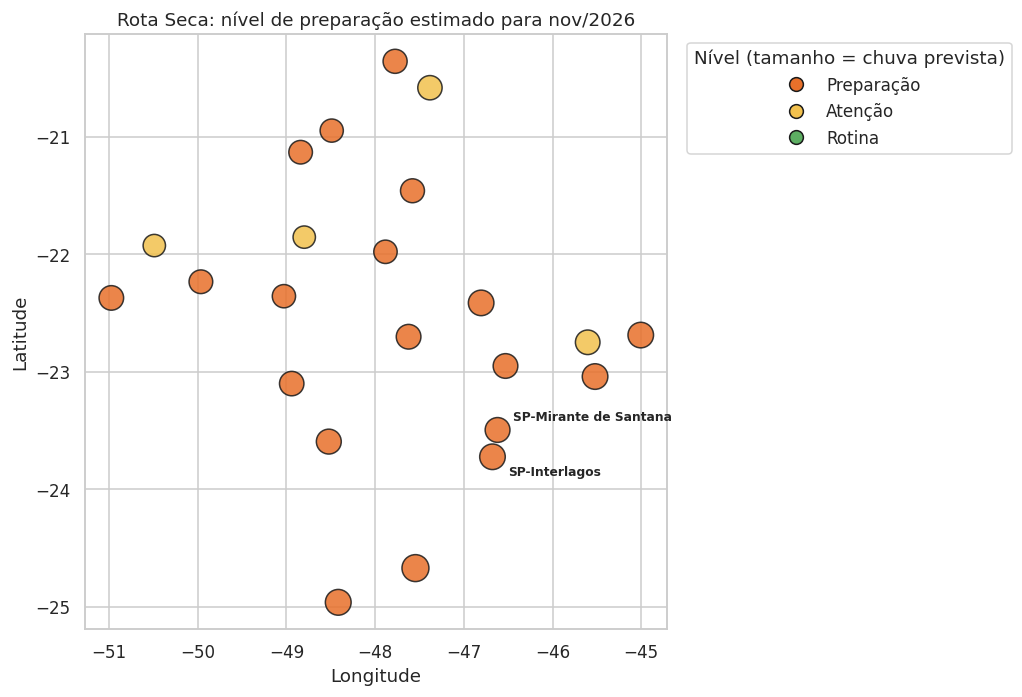

In [24]:
fig, ax = plt.subplots(figsize=(9.5, 6.5))
cores = atual['prob_dia_50mm'].apply(lambda p: '#E8702A' if p >= 0.65 else ('#F2C14E' if p >= 0.40 else '#5DAE62'))
ax.scatter(atual['lon'], atual['lat'], s=60 + atual['chuva_prevista_mm'], c=cores, edgecolor='k', alpha=0.85)
for (cod, nome), desloc in zip(capital.items(), [(10, 6), (10, -12)]):
    r = atual[atual['codigo'] == cod]
    if len(r):
        ax.annotate(nome.replace('São Paulo - ', 'SP-'), (r['lon'].iloc[0], r['lat'].iloc[0]),
                    xytext=desloc, textcoords='offset points', fontsize=8, weight='bold')
from matplotlib.lines import Line2D
leg = [Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markeredgecolor='k', markersize=9, label=l)
       for c, l in [('#E8702A', 'Preparação'), ('#F2C14E', 'Atenção'), ('#5DAE62', 'Rotina')]]
ax.legend(handles=leg, title='Nível (tamanho = chuva prevista)', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=True)
ax.set(title='Rota Seca: nível de preparação estimado para nov/2026', xlabel='Longitude', ylabel='Latitude')
plt.tight_layout(); plt.show()

### O que a estimativa diz

- **Outubro de 2026 foi muito chuvoso na capital**: 256,8 mm no Mirante de Santana e 271,2 mm em Interlagos.
- Para **novembro de 2026**, o modelo estima cerca de **204 mm no Mirante** e **220 mm em Interlagos**. São valores **64% e 78% acima da média de novembro de 2020 a 2025** (cerca de 124 mm nas duas estações).
- A probabilidade estimada de pelo menos um dia com 50 mm ou mais é de **0,73 (Mirante)** e **0,75 (Interlagos)**, o que coloca as duas estações da capital no nível **🟠 Preparação**.
- No estado, **19 das 23 estações** com dado completo em outubro ficaram em Preparação e 4 em Atenção. Isso é coerente com dois fatores que o modelo considera importantes: novembro é início da estação chuvosa e outubro foi muito úmido.
- Só 23 das 43 estações tinham cobertura de chuva suficiente (≥ 80%) em outubro. Para bairros cuja estação mais próxima está sem dado, a Rota Seca deve usar a estação válida mais próxima.

Isto é uma **estimativa do modelo**, e não uma previsão oficial. Como novembro de 2026 está em andamento, a própria equipe pode conferir o resultado no fim do mês, comparando com os dados do INMET.

## 9. Recomendações de ação, impactos e limitações

### 9.1 Ações recomendadas a partir das previsões

1. **Usar a probabilidade da regressão logística como gatilho do "modo preparação".** Quando a estação que cobre o bairro passar de 0,65:
   - priorizar na zeladoria colaborativa da Rota Seca os registros de bueiros entupidos e lixo nas ruas mapeadas como pontos de alagamento;
   - confirmar com a subprefeitura e a Defesa Civil que os pontos de apoio (escolas, UBS, abrigos) estarão abertos;
   - enviar ao morador cadastrado um lembrete para revisar sua rota segura.

   **Para novembro de 2026, as duas estações da capital estão nesse nível, então a recomendação é ativar o modo preparação já** no bairro piloto.

2. **Priorizar bairros pelo ranking de probabilidade.** Equipes de zeladoria e agentes são limitados. O ranking da seção 8 indica onde agir primeiro e pode alimentar o cálculo de rotas seguras da Rota Seca (parte de Dynamic Programming), dando peso maior às ruas próximas de estações em Preparação.

3. **Usar a chuva prevista pela regressão linear como sinal de "acima ou abaixo do normal".** Comparar a previsão com a média histórica do mesmo mês ajuda a dimensionar a resposta: quanto maior a anomalia, mais kits, voluntários e mensagens. Em novembro de 2026, a capital está entre 64% e 78% acima do normal. Como o modelo subestima meses extremos, o número deve ser lido como **direção e intensidade relativa**, não como volume exato.

4. **Manter o limiar com viés para o recall e revisá-lo periodicamente.** O custo de não avisar é maior que o de preparar à toa. A cada trimestre, com novos meses de dados, a equipe deve reavaliar o limiar. Em bairros com histórico grave, faz sentido baixar para 0,4 (recall de 81% no teste).

5. **Não substituir os avisos oficiais de curto prazo.** O modelo é mensal. Para as horas que antecedem a chuva, a Rota Seca deve repassar os avisos do INMET (alertas2.inmet.gov.br) e incentivar o cadastro no SMS da Defesa Civil (enviar o CEP para 40199).

6. **Comunicar de forma simples.** O morador não precisa ver "probabilidade 0,73". A mensagem deve ser direta e acessível, por exemplo: *"Novembro deve ter dias de chuva forte no seu bairro. Confira sua rota segura e o ponto de apoio mais perto."* Letras grandes e linguagem simples, pensando em idosos.

### 9.2 Impacto esperado e indicadores

- **Antecedência:** no período de teste, **108 de 145 meses perigosos (74,5%)** teriam sido sinalizados com um mês de antecedência, quase o dobro do que uma escolha ao acaso conseguiria.
- **Indicadores para a Ficha da CitizenTech:**
  - % de meses com evento ≥ 50 mm sinalizados com antecedência (recall; meta ≥ 70%);
  - % de sinalizações confirmadas (precisão; acompanhar para evitar "fadiga de alerta");
  - nº de bueiros e pontos de lixo resolvidos antes de meses em Preparação;
  - nº de moradores cadastrados que revisaram a rota segura;
  - ocorrências de alagamento nos pontos monitorados, comparadas ao mesmo período do ano anterior.
- **Impacto social:** o foco em moradores de áreas de risco, que costumam ser os mais vulneráveis, conecta o projeto ao **ODS 10**, à **meta 11.5** (reduzir perdas por desastres) e à **meta 13.1** (resiliência a riscos climáticos).

### 9.3 Limitações dos modelos

1. **Escala de tempo:** o modelo prevê o mês, mas alagamentos acontecem em horas. Ele serve para planejar, não para alertar em tempo real.
2. **Alvo indireto:** um dia com 50 mm não é sinônimo de alagamento. O alagamento também depende de drenagem, impermeabilização e lixo. A base não tem registros de alagamento.
3. **Estação x bairro:** a capital tem só duas estações nesta base (Mirante e Interlagos), e a chuva varia muito dentro da cidade. Um bairro pode ter um temporal que a estação não registra.
4. **Série curta e com lacunas:** são cerca de 6 anos (2020 a 2026), com 31,7% dos meses sem dado de chuva. Fenômenos como El Niño e La Niña não estão representados de forma explícita.
5. **Limites da regressão linear:** subestima meses extremos (máximo previsto de 272 mm contra 574 mm reais), tem erro maior nos meses chuvosos e pode gerar valores negativos, que foram cortados para 0.
6. **Probabilidades não calibradas:** por causa do balanceamento de classes, a probabilidade serve para ordenar e priorizar, não como chance exata.
7. **Colinearidade:** variáveis de chuva e de temperatura são correlacionadas entre si, então os coeficientes individuais devem ser lidos com cautela.
8. **Mudança do clima:** o padrão de chuva pode mudar ao longo do tempo, e o modelo precisa ser reavaliado com frequência.
9. **Dados consolidados por terceiros:** usamos a agregação mensal do repositório *analiseclimatica*, feita a partir do INMET. Conferimos as regras de qualidade no script, mas não refizemos a agregação.

### 9.4 Próximos passos

- Cruzar com os registros de alagamento do CGE (Centro de Gerenciamento de Emergências de São Paulo) para treinar o alvo "alagou ou não".
- Usar dados diários ou horários e previsões numéricas do tempo para horizontes de dias.
- Incluir índices climáticos (ENSO).
- Comparar com modelos não lineares (random forest, gradient boosting).
- Calibrar as probabilidades da regressão logística.

## 10. Conclusão e referências

### Conclusão

- A **sazonalidade** é o principal fator para prever o volume e o risco de chuva extrema no estado de São Paulo (**H1 confirmada**).
- A chuva do mês atual tem um efeito positivo de **persistência**, embora menor (**H2 parcialmente confirmada**).
- A **localização** das estações também importa (**H3 confirmada**).

Sobre os modelos:
- A **regressão linear** (R² de 0,44 e MAE de 54 mm no teste) erra cerca de 30% menos que a média simples e fica no nível da climatologia. É útil para indicar se o próximo mês tende a ficar acima ou abaixo do normal.
- A **regressão logística** (recall de 74,5%, F1 de 0,55 e AUC de 0,78 no teste) identifica com um mês de antecedência 3 de cada 4 meses com chuva de nível "Perigo".

Na Rota Seca, essa probabilidade vira o **nível de preparação** de cada região. Esse nível pode ser gravado na tabela de alertas do banco de dados e exposto pela API Java, e o ranking de regiões alimenta o cálculo de rotas seguras. A estimativa para **novembro de 2026** coloca a capital em **🟠 Preparação**.

### Referências

- INMET. *Dados Históricos: estações automáticas.* https://portal.inmet.gov.br/dadoshistoricos
- Repositório *analiseclimatica* (consolidação mensal SP/MG dos dados do INMET). https://github.com/esthelaalmeida2025-rgb/analiseclimatica
- INMET. *Avisos meteorológicos* (níveis amarelo, laranja e vermelho de acumulado de chuva). https://alertas2.inmet.gov.br
- Scikit-learn. *User Guide: Linear Models, Model Evaluation.* https://scikit-learn.org/stable/user_guide.html
- ONU Brasil. *Objetivos de Desenvolvimento Sustentável.* https://brasil.un.org/pt-br/sdgs